In [7]:

%pip install pandas numpy matplotlib seaborn scikit-learn joblib datasets pyarrow

Note: you may need to restart the kernel to use updated packages.


In [8]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import ast
import joblib

from pathlib import Path
from collections import Counter

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Set visualization style
sns.set_style("whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
# Step 3: Create folders for our project

os.makedirs("dataset", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [13]:
# Step 4: Load the job posting dataset

df = pd.read_csv(r"C:\Users\pc\job_postings.csv")

# Display dataset information
print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

# Display first five rows
df.head()

Dataset loaded successfully!
Total Rows: 785741
Total Columns: 17


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


In [14]:
# Step 5: Explore dataset columns and information

# Display column names
print("Dataset Columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Columns:
['job_title_short', 'job_title', 'job_location', 'job_via', 'job_schedule_type', 'job_work_from_home', 'search_location', 'job_posted_date', 'job_no_degree_mention', 'job_health_insurance', 'job_country', 'salary_rate', 'salary_year_avg', 'salary_hour_avg', 'company_name', 'job_skills', 'job_type_skills']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785741 entries, 0 to 785740
Data columns (total 17 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   job_title_short        785741 non-null  object 
 1   job_title              785740 non-null  object 
 2   job_location           784696 non-null  object 
 3   job_via                785733 non-null  object 
 4   job_schedule_type      773074 non-null  object 
 5   job_work_from_home     785741 non-null  bool   
 6   search_location        785741 non-null  object 
 7   job_posted_date        785741 non-null  object 
 8   job_no_d

In [15]:
# Step 6: Remove duplicate records

df = df.drop_duplicates()

print("Duplicates removed!")
print("Dataset shape:", df.shape)

Duplicates removed!
Dataset shape: (785640, 17)


In [16]:
# Remove rows with missing essential information

df = df.dropna(
    subset=[
        "job_title_short",
        "job_posted_date"
    ]
)

print("Missing essential records removed!")
print("Dataset shape:", df.shape)

Missing essential records removed!
Dataset shape: (785640, 17)


In [17]:
# Convert posting date into datetime format

df["job_posted_date"] = pd.to_datetime(
    df["job_posted_date"],
    errors="coerce",
    utc=True
)

# Remove invalid dates
df = df.dropna(subset=["job_posted_date"])

# Remove timezone information
df["job_posted_date"] = (
    df["job_posted_date"].dt.tz_convert(None)
)

print("Date conversion completed!")

Date conversion completed!


In [18]:
# Clean job titles

df["job_title_short"] = (
    df["job_title_short"]
    .astype(str)
    .str.strip()
)

# Clean job locations
if "job_location" in df.columns:
    df["job_location"] = (
        df["job_location"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
    )

print("Text cleaning completed!")

df.head()

Text cleaning completed!


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


In [19]:
# Save cleaned dataset

df.to_csv(
    "dataset/cleaned_job_postings.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


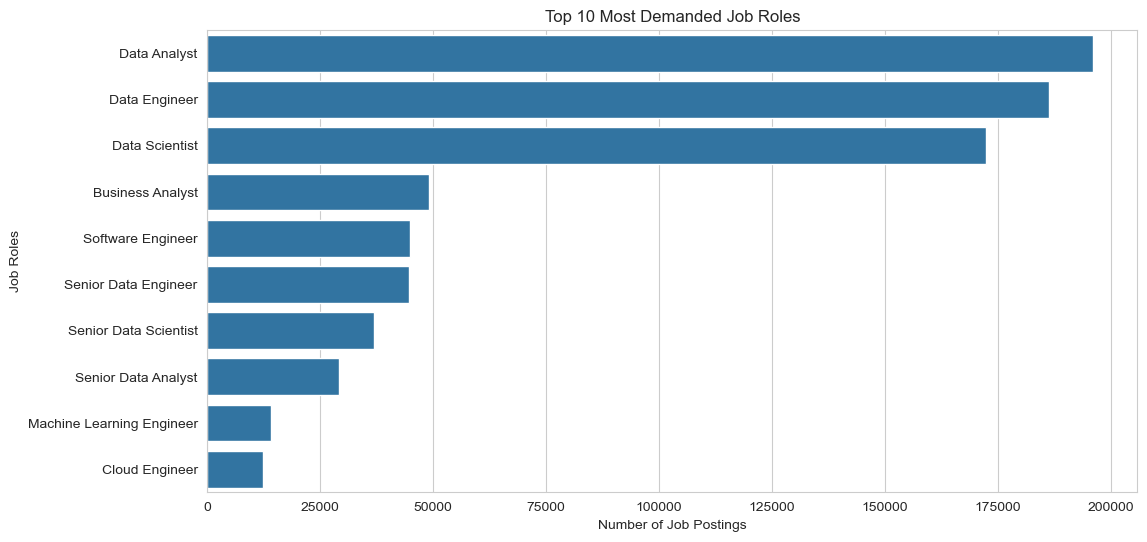

In [20]:
# Find the top 10 most demanded job roles

top_jobs = df["job_title_short"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_jobs.values,
    y=top_jobs.index
)

plt.title("Top 10 Most Demanded Job Roles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Roles")

plt.show()

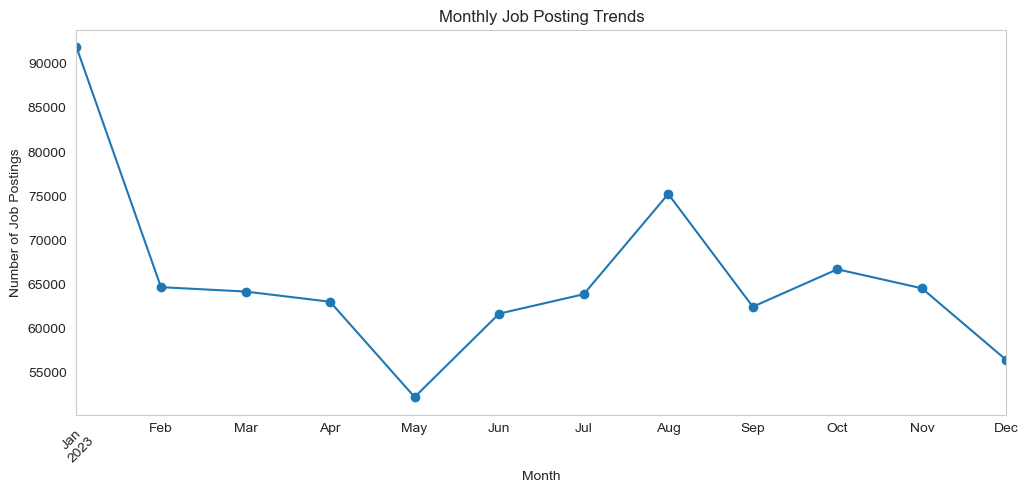

In [21]:
# Analyze monthly job posting trends

df["month"] = df["job_posted_date"].dt.to_period("M")

monthly_jobs = df.groupby("month").size()

plt.figure(figsize=(12, 5))

monthly_jobs.plot(marker="o")

plt.title("Monthly Job Posting Trends")
plt.xlabel("Month")
plt.ylabel("Number of Job Postings")

plt.xticks(rotation=45)
plt.grid()

plt.show()

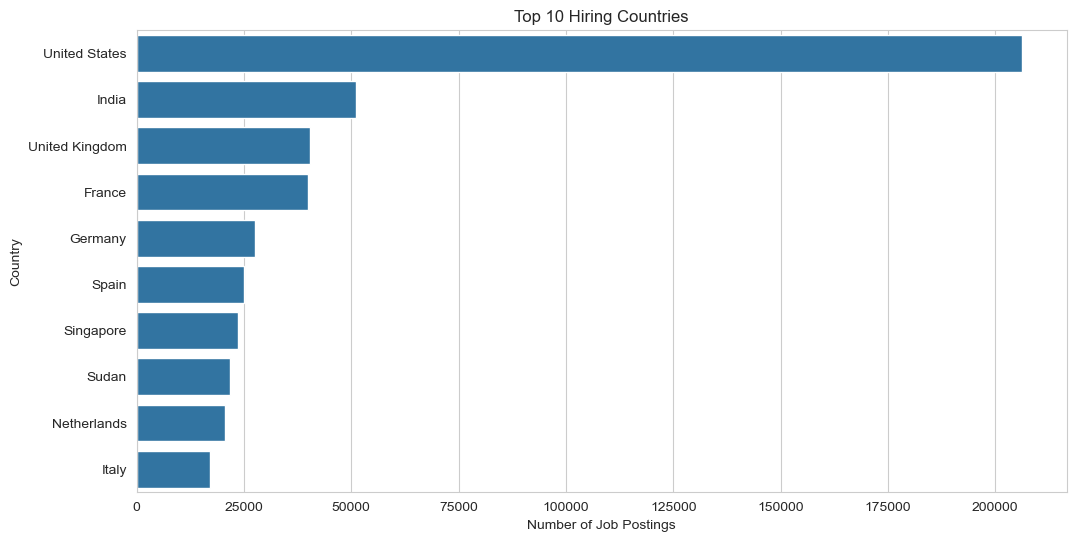

In [22]:
# Analyze job demand by country

top_countries = df["job_country"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Hiring Countries")
plt.xlabel("Number of Job Postings")
plt.ylabel("Country")

plt.show()

In [24]:
# Convert job skills into Python lists

def extract_skills(value):

    if isinstance(value, list):
        return [
            str(skill).lower().strip()
            for skill in value
        ]

    if pd.isna(value):
        return []

    try:
        skills = ast.literal_eval(value)

        if isinstance(skills, list):
            return [
                str(skill).lower().strip()
                for skill in skills
            ]

    except (ValueError, SyntaxError):
        return []

    return []


df["skills_list"] = df["job_skills"].apply(
    extract_skills
)

print("Skills extracted successfully!")

df[["job_title_short", "skills_list"]].head()

Skills extracted successfully!


,job_title_short,skills_list
0,Senior Data Engineer,[]
1,Data Analyst,"[r, python, sql, nosql, power bi, tableau]"
2,Data Engineer,"[python, sql, c#, azure, airflow, dax, docker,..."
3,Data Engineer,"[python, c++, java, matlab, aws, tensorflow, k..."
4,Data Engineer,"[bash, python, oracle, aws, ansible, puppet, j..."


In [25]:
# Count the frequency of each skill

all_skills = []

for skills in df["skills_list"]:

    all_skills.extend(set(skills))


skill_counts = Counter(all_skills)

top_skills = skill_counts.most_common(15)

skill_df = pd.DataFrame(
    top_skills,
    columns=["Skill", "Frequency"]
)

display(skill_df)

,Skill,Frequency
0,sql,384822
1,python,380883
2,aws,145377
3,azure,132525
4,r,130884
5,tableau,127207
6,excel,127011
7,spark,114604
8,power bi,98141
9,java,85607


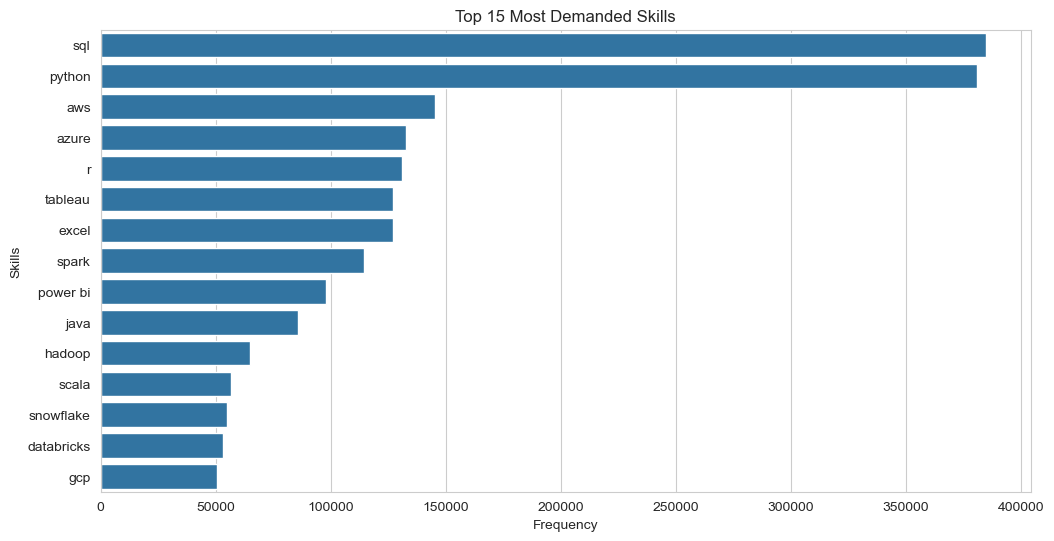

In [26]:
# Plot the top 15 demanded skills

plt.figure(figsize=(12, 6))

sns.barplot(
    data=skill_df,
    x="Frequency",
    y="Skill"
)

plt.title("Top 15 Most Demanded Skills")
plt.xlabel("Frequency")
plt.ylabel("Skills")

plt.show()

In [27]:
# Calculate monthly skill demand

skill_records = []

for _, row in df.iterrows():

    for skill in set(row["skills_list"]):

        skill_records.append({
            "date": row["job_posted_date"],
            "skill": skill
        })


skill_data = pd.DataFrame(skill_records)

skill_data["month"] = (
    skill_data["date"].dt.to_period("M")
)

monthly_skills = (
    skill_data.groupby(["month", "skill"])
    .size()
    .unstack(fill_value=0)
)

# Calculate skill growth

skill_trends = []

for skill in monthly_skills.columns:

    first_average = monthly_skills[skill].iloc[:3].mean()

    last_average = monthly_skills[skill].iloc[-3:].mean()

    if first_average == 0:

        growth = np.nan
        trend = "Insufficient baseline"

    else:

        growth = (
            (last_average - first_average)
            / first_average
        ) * 100

        if growth > 10:
            trend = "Increasing"

        elif growth < -10:
            trend = "Decreasing"

        else:
            trend = "Stable"

    skill_trends.append({
        "Skill": skill,
        "Growth": growth,
        "Trend": trend
    })


skill_trend_df = pd.DataFrame(skill_trends)

skill_trend_df = skill_trend_df.sort_values(
    "Growth",
    ascending=False
)

display(skill_trend_df.head(20))

,Skill,Growth,Trend
75,gatsby,400.000000,Increasing
67,fastify,333.333333,Increasing
141,nuix,280.000000,Increasing
120,microsoft lists,200.000000,Increasing
27,chainer,150.000000,Increasing
123,mlpack,125.000000,Increasing
52,dlib,100.000000,Increasing
93,hugging face,88.271605,Increasing
145,ocaml,85.714286,Increasing
248,wsl,60.000000,Increasing


In [28]:
# Select a job role for demand prediction

selected_role = "Data Analyst"

role_df = df[
    df["job_title_short"] == selected_role
].copy()

print("Selected Job Role:", selected_role)

print("Total Job Postings:", len(role_df))

Selected Job Role: Data Analyst
Total Job Postings: 196050


In [29]:
# Aggregate job postings by week

weekly_demand = (
    role_df
    .set_index("job_posted_date")
    .resample("W")
    .size()
)

weekly_demand = weekly_demand.asfreq(
    "W",
    fill_value=0
)

print("Weekly demand data:")
display(weekly_demand.head(10))

Weekly demand data:


job_posted_date
2023-01-01     867
2023-01-08    5109
2023-01-15    5403
2023-01-22    5363
2023-01-29    5339
2023-02-05    4632
2023-02-12    4378
2023-02-19    4056
2023-02-26    3818
2023-03-05    3891
Freq: W-SUN, dtype: int64

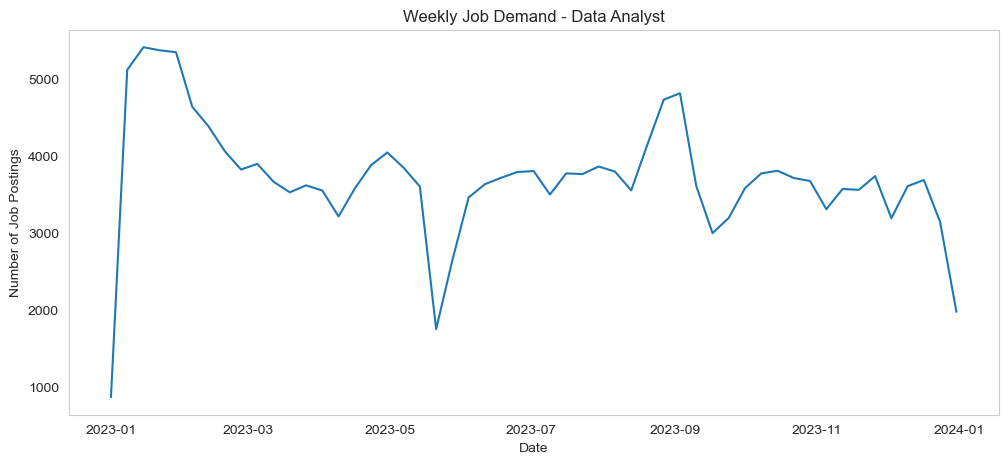

In [30]:
# Visualize historical weekly demand

plt.figure(figsize=(12, 5))

plt.plot(
    weekly_demand.index,
    weekly_demand.values
)

plt.title("Weekly Job Demand - " + selected_role)

plt.xlabel("Date")
plt.ylabel("Number of Job Postings")

plt.grid()

plt.show()

In [31]:
# Create machine learning features

ml_data = pd.DataFrame()

ml_data["demand"] = weekly_demand

# Previous demand
ml_data["lag_1"] = ml_data["demand"].shift(1)

ml_data["lag_2"] = ml_data["demand"].shift(2)

ml_data["lag_4"] = ml_data["demand"].shift(4)

ml_data["lag_8"] = ml_data["demand"].shift(8)

# Moving averages
ml_data["rolling_mean_4"] = (
    ml_data["demand"]
    .shift(1)
    .rolling(4)
    .mean()
)

ml_data["rolling_mean_8"] = (
    ml_data["demand"]
    .shift(1)
    .rolling(8)
    .mean()
)

# Remove missing values
ml_data = ml_data.dropna()

display(ml_data.head())

,demand,lag_1,lag_2,lag_4,lag_8,rolling_mean_4,rolling_mean_8
job_posted_date,,,,,,,
2023-02-26,3818,4056.0,4378.0,5339.0,867.0,4601.25,4393.375
2023-03-05,3891,3818.0,4056.0,4632.0,5109.0,4221.00,4762.250
2023-03-12,3660,3891.0,3818.0,4378.0,5403.0,4035.75,4610.000
2023-03-19,3522,3660.0,3891.0,4056.0,5363.0,3856.25,4392.125
2023-03-26,3613,3522.0,3660.0,3818.0,5339.0,3722.75,4162.000


In [32]:
# Separate input features and target

X = ml_data.drop(columns=["demand"])

y = ml_data["demand"]

# Split chronologically (80% training, 20% testing)

split_index = int(len(ml_data) * 0.8)

X_train = X.iloc[:split_index]

X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]

y_test = y.iloc[split_index:]


print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (36, 6)
Testing Data: (9, 6)


In [33]:
# Create machine learning models

models = {

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )

}

print("Models created successfully!")

Models created successfully!


In [34]:
# Train and evaluate all machine learning models

results = []

trained_models = {}

# Baseline: previous week's demand
baseline_predictions = X_test["lag_1"]

results.append({
    "Model": "Naive Baseline",
    "MAE": mean_absolute_error(
        y_test,
        baseline_predictions
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            y_test,
            baseline_predictions
        )
    ),
    "R2": r2_score(
        y_test,
        baseline_predictions
    )
})


for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Make predictions
    predictions = model.predict(X_test)

    predictions = np.maximum(predictions, 0)

    # Evaluate model
    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    # Store results
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = model


results_df = pd.DataFrame(results)

results_df = results_df.sort_values("MAE")

display(results_df)

,Model,MAE,RMSE,R2
2,Random Forest,393.449908,626.967858,-0.498529
1,Linear Regression,393.628717,538.113061,-0.103879
0,Naive Baseline,396.222222,512.195709,-0.000107
3,Gradient Boosting,402.734303,637.572798,-0.549652


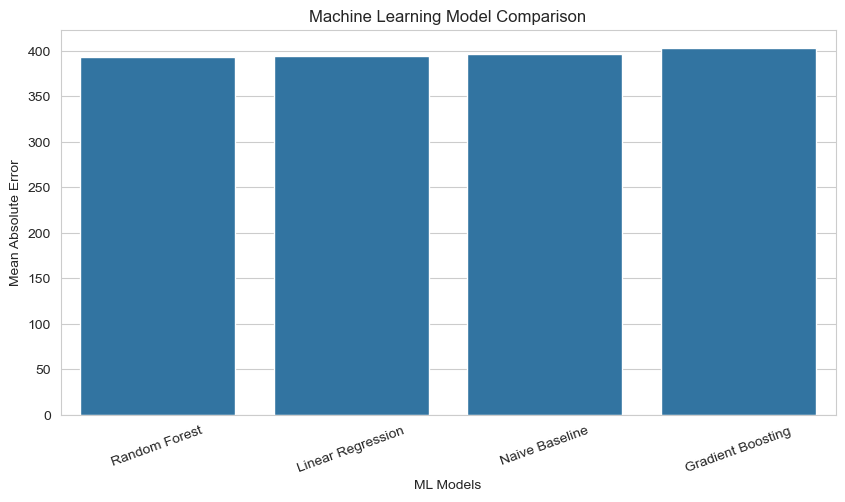

In [35]:
# Display model performance comparison

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("Machine Learning Model Comparison")

plt.xlabel("ML Models")
plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=20)

plt.show()

Best ML Model: Random Forest


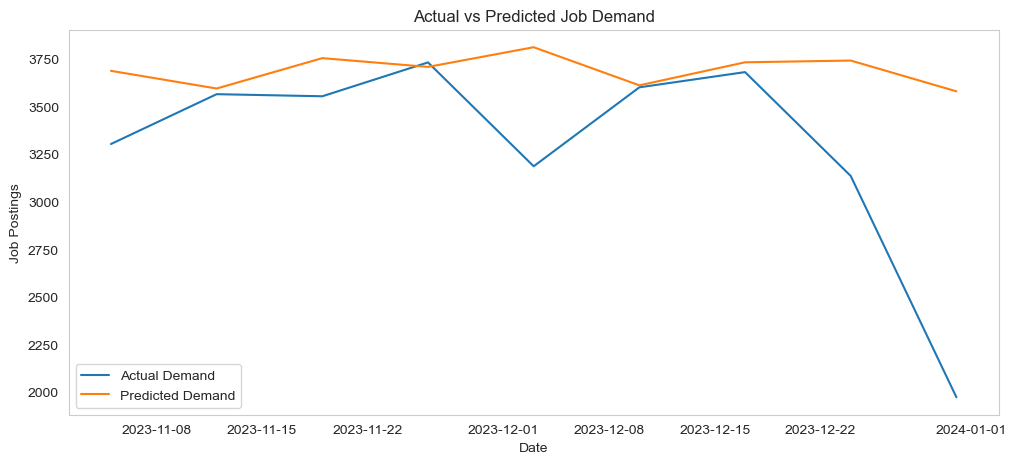

In [36]:
# Select the best ML model based on MAE

best_model_name = (
    results_df[
        results_df["Model"] != "Naive Baseline"
    ].iloc[0]["Model"]
)

best_model = trained_models[best_model_name]

# Generate predictions
predictions = np.maximum(
    best_model.predict(X_test),
    0
)

print("Best ML Model:", best_model_name)


# Compare actual and predicted values

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Demand"
)

plt.plot(
    y_test.index,
    predictions,
    label="Predicted Demand"
)

plt.title("Actual vs Predicted Job Demand")

plt.xlabel("Date")
plt.ylabel("Job Postings")

plt.legend()
plt.grid()

plt.show()

In [37]:
# Predict future job demand for 26 weeks

def create_features(history):

    return pd.DataFrame([{

        "lag_1": history.iloc[-1],

        "lag_2": history.iloc[-2],

        "lag_4": history.iloc[-4],

        "lag_8": history.iloc[-8],

        "rolling_mean_4": history.iloc[-4:].mean(),

        "rolling_mean_8": history.iloc[-8:].mean()

    }])


history = weekly_demand.copy()

future_predictions = []

for i in range(26):

    # Prepare input features
    next_features = create_features(history)

    # Predict next week
    prediction = best_model.predict(next_features)[0]

    prediction = max(0, prediction)

    future_predictions.append(prediction)

    # Add prediction to historical sequence
    next_date = history.index[-1] + pd.Timedelta(days=7)

    history.loc[next_date] = prediction


# Create future dates
future_dates = pd.date_range(
    start=weekly_demand.index[-1] + pd.Timedelta(days=7),
    periods=26,
    freq="W"
)

# Create forecast dataframe
forecast_df = pd.DataFrame({

    "Date": future_dates,

    "Predicted Demand": future_predictions

})

display(forecast_df)

,Date,Predicted Demand
0,2024-01-07,3475.792000
1,2024-01-14,3574.427494
2,2024-01-21,3753.195671
3,2024-01-28,3777.614575
4,2024-02-04,3774.040212
5,2024-02-11,3731.756940
6,2024-02-18,3761.644310
7,2024-02-25,3768.017524
8,2024-03-03,3763.195667
9,2024-03-10,3695.238262


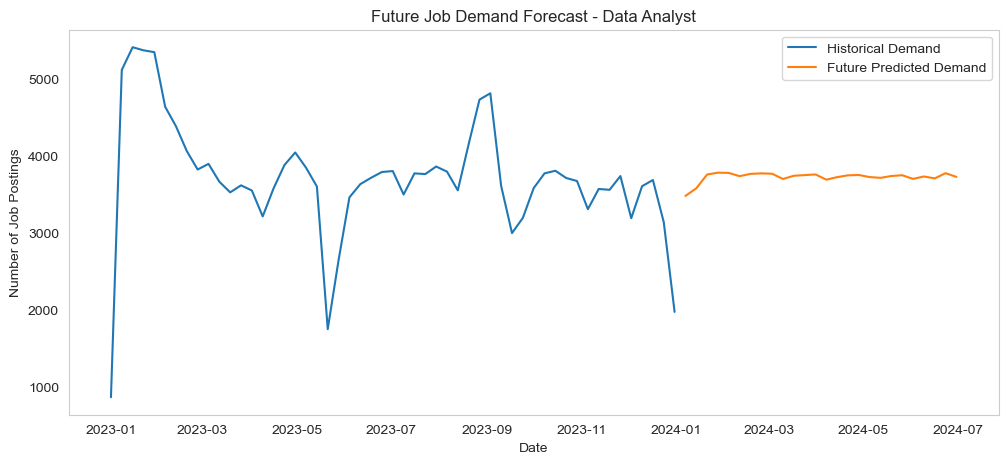

In [38]:
# Visualize future job demand prediction

plt.figure(figsize=(12, 5))

plt.plot(
    weekly_demand.index,
    weekly_demand.values,
    label="Historical Demand"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted Demand"],
    label="Future Predicted Demand"
)

plt.title("Future Job Demand Forecast - " + selected_role)

plt.xlabel("Date")
plt.ylabel("Number of Job Postings")

plt.legend()
plt.grid()

plt.show()

In [39]:
# Save the best trained model

joblib.dump(
    best_model,
    "models/job_demand_model.pkl"
)

# Save feature names
joblib.dump(
    list(X_train.columns),
    "models/model_features.pkl"
)

# Save model information
joblib.dump(
    {
        "selected_role": selected_role,
        "best_model": best_model_name
    },
    "models/model_metadata.pkl"
)

print("Machine Learning Model Saved Successfully!")

Machine Learning Model Saved Successfully!


In [40]:
# Save ML outputs as CSV files

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

forecast_df.to_csv(
    "outputs/future_demand_prediction.csv",
    index=False
)

skill_trend_df.to_csv(
    "outputs/skill_trends.csv",
    index=False
)

skill_df.to_csv(
    "outputs/top_skills.csv",
    index=False
)

print("All ML results saved successfully!")

All ML results saved successfully!
